<a href="https://colab.research.google.com/github/DariaToguleva/fcnet-lstm-attention/blob/main/HW1_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(0)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)

plt.rcParams.update({
    "figure.figsize": (11, 3.5), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})

torch 2.11.0+cpu | device: cpu


In [ ]:
DATA_PATH = "202608MD.csv"
SERIES    = "S&P 500"
DATE_COL  = "sasdate"

P_LAGS    = 12
VAL_FRAC  = 0.15
TEST_FRAC = 0.15
REVIN_EPS = 1e-8

In [ ]:
import os

if not os.path.exists(DATA_PATH):
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]

print("using:", DATA_PATH)

Saving 2026-08-MD.csv to 2026-08-MD (2).csv
using: 2026-08-MD (2).csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def apply_tcode(x, code):
    lx = np.log(x)
    return {
        1: x,
        2: x.diff(),
        3: x.diff().diff(),
        4: lx,
        5: lx.diff(),
        6: lx.diff().diff(),
        7: (x / x.shift(1) - 1.0).diff(),
    }[int(code)]

In [ ]:
_file = pd.read_csv(DATA_PATH)
TCODE = int(_file.iloc[0][SERIES])

body = _file.iloc[1:].copy()
body[DATE_COL] = pd.to_datetime(body[DATE_COL], errors="coerce")
body = body.dropna(subset=[DATE_COL]).sort_values(DATE_COL).reset_index(drop=True)

levels = pd.to_numeric(body[SERIES], errors="coerce")
series = pd.DataFrame({
    DATE_COL: body[DATE_COL],
    "level":  levels,
    SERIES:   apply_tcode(levels, TCODE),
}).dropna().reset_index(drop=True)

gaps = (series[DATE_COL].diff().dt.days.dropna() > 32).sum()
assert gaps == 0, f"{gaps} calendar gap(s) after dropna -- windows would span them"

dates   = series[DATE_COL].values
y_level = series["level"].to_numpy(dtype=np.float32)
y       = series[SERIES].to_numpy(dtype=np.float32)

print(f"Series              : {SERIES}   (transform code {TCODE})")
print(f"Usable observations : {len(y)}")
print(f"Date range          : {str(dates[0])[:7]} to {str(dates[-1])[:7]}")

Series              : S&P 500   (transform code 5)
Usable observations : 810
Date range          : 1959-02 to 2026-07


In [ ]:
def lag1_autocorr(x):
    return float(np.corrcoef(x[:-1], x[1:])[0, 1])

desc = pd.Series({
    "n_obs": len(y), "mean": y.mean(), "median": np.median(y),
    "std": y.std(ddof=1), "min": y.min(), "max": y.max(),
    "lag1_autocorr": lag1_autocorr(y),
})
print(f"--- Descriptive statistics: {SERIES} ---")
print(desc.to_string(float_format=lambda v: f"{v:,.6g}"))

--- Descriptive statistics: S&P 500 ---
n_obs                  810
mean            0.00605139
median          0.00961804
std              0.0357029
min              -0.228045
max               0.113523
lag1_autocorr     0.222609


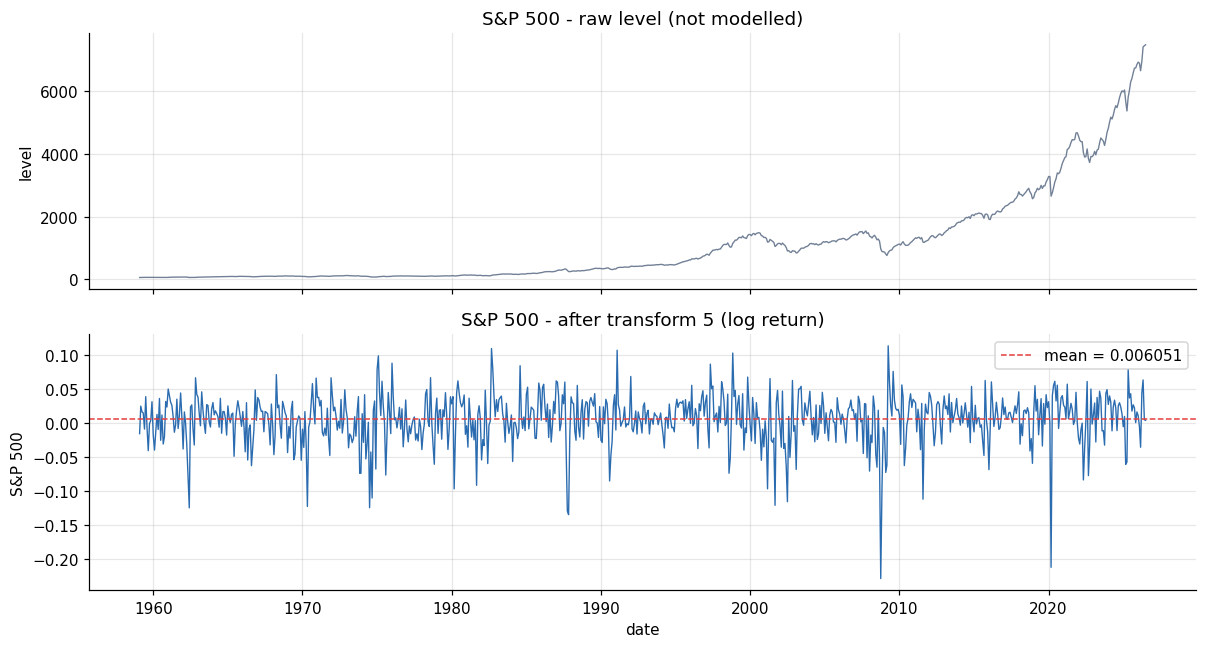

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

axes[0].plot(dates, y_level, lw=0.9, color="#718096")
axes[0].set_title(f"{SERIES} - raw level (not modelled)")
axes[0].set_ylabel("level")

axes[1].plot(dates, y, lw=0.9, color="#2b6cb0")
axes[1].axhline(y.mean(), color="#e53e3e", lw=1, ls="--", label=f"mean = {y.mean():.4g}")
axes[1].set_title(f"{SERIES} - after transform {TCODE} (log return)")
axes[1].set_xlabel("date"); axes[1].set_ylabel(SERIES); axes[1].legend()

plt.tight_layout(); plt.show()

In [ ]:
def make_windows(y, p):
    y = np.asarray(y, dtype=np.float32).ravel()
    T = len(y)
    if T <= p:
        raise ValueError(f"Need more than p={p} observations, got T={T}.")
    N = T - p
    X = np.lib.stride_tricks.sliding_window_view(y, p)[:N]
    Y = y[p:]
    idx = np.arange(p, T)
    return np.ascontiguousarray(X, dtype=np.float32), Y.astype(np.float32), idx

X, Y, idx = make_windows(y, P_LAGS)
print(f"X {X.shape}   Y {Y.shape}   (from {len(y)} observations, p = {P_LAGS})")

X (798, 12)   Y (798,)   (from 810 observations, p = 12)


In [ ]:
def chrono_split(n, val_frac, test_frac):
    n_test  = int(round(test_frac * n))
    n_val   = int(round(val_frac * n))
    n_train = n - n_val - n_test
    if min(n_train, n_val, n_test) < 1:
        raise ValueError(f"Split leaves an empty set: {n_train}/{n_val}/{n_test}")
    order = np.arange(n)
    return (order < n_train,
            (order >= n_train) & (order < n_train + n_val),
            order >= n_train + n_val)

tr_m, va_m, te_m = chrono_split(len(Y), VAL_FRAC, TEST_FRAC)
assert idx[tr_m].max() < idx[va_m].min()
assert idx[va_m].max() < idx[te_m].min()

tgt_dates = dates[idx]
for name, m in [("train", tr_m), ("val", va_m), ("test", te_m)]:
    d = tgt_dates[m]
    print(f"{name:5s} n={m.sum():4d}   targets {str(d[0])[:7]} .. {str(d[-1])[:7]}")

train n= 558   targets 1960-02 .. 2006-07
val   n= 120   targets 2006-08 .. 2016-07
test  n= 120   targets 2016-08 .. 2026-07


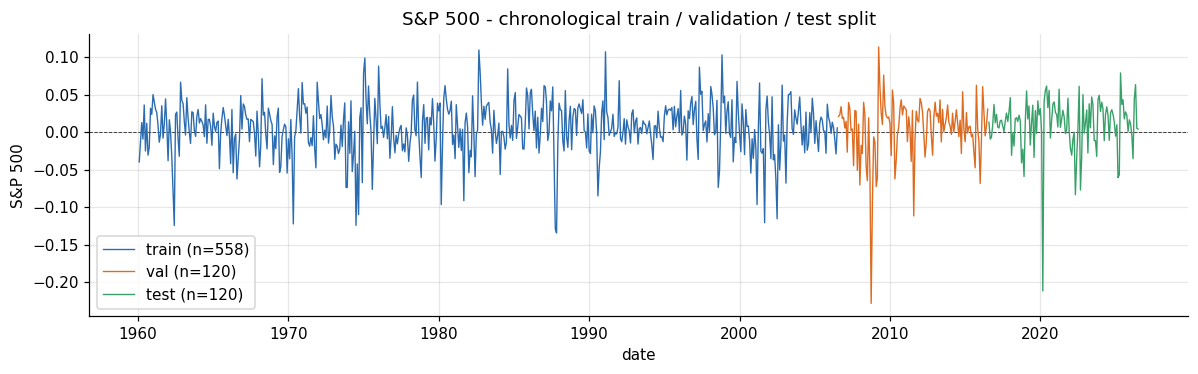

In [ ]:
fig, ax = plt.subplots()
for name, m, c in [("train", tr_m, "#2b6cb0"), ("val", va_m, "#dd6b20"), ("test", te_m, "#38a169")]:
    ax.plot(tgt_dates[m], Y[m], lw=0.9, color=c, label=f"{name} (n={m.sum()})")
ax.set_title(f"{SERIES} - chronological train / validation / test split")
ax.set_xlabel("date"); ax.set_ylabel(SERIES); ax.legend()
ax.axhline(0, color="k", lw=0.6, ls="--", zorder=0)
plt.tight_layout(); plt.show()

In [ ]:
split_stats = pd.DataFrame({
    name: {"n": int(m.sum()), "mean": Y[m].mean(), "std": Y[m].std(ddof=1),
           "min": Y[m].min(), "max": Y[m].max(), "ac1": lag1_autocorr(Y[m]),
           "d_std": np.diff(Y[m]).std(ddof=1)}
    for name, m in [("train", tr_m), ("val", va_m), ("test", te_m)]
}).T
print(split_stats.to_string(float_format=lambda v: f"{v:,.6g}"))
print(f"\ntest std / train std = {Y[te_m].std(ddof=1) / Y[tr_m].std(ddof=1):.2f}x")

        n       mean       std       min       max       ac1     d_std
train 558  0.0055163 0.0347055 -0.134245  0.109545  0.237245 0.0428714
val   120 0.00444712 0.0408995 -0.228045  0.113523  0.271664 0.0495106
test  120  0.0103955 0.0358201 -0.211562 0.0790041 0.0884549 0.0485658

test std / train std = 1.03x


In [ ]:
X_test = X[te_m]
Y_test = Y[te_m]

pred_persistence = X_test[:, -1]

train_mean = Y[tr_m].mean()
pred_mean = np.full(len(Y_test), train_mean, dtype=np.float32)

A_train = np.c_[np.ones(tr_m.sum()), X[tr_m]]
ar_coef, *_ = np.linalg.lstsq(A_train, Y[tr_m], rcond=None)
pred_ar = np.c_[np.ones(len(Y_test)), X_test] @ ar_coef

HUBER_DELTA = 0.5 * float(np.mean(np.abs(np.diff(Y[tr_m]))))

print("X_test", X_test.shape, " Y_test", Y_test.shape)
print(f"training mean = {train_mean:.6f}")
print(f"AR intercept  = {ar_coef[0]:.6f}")
lag_labels = [f"lag{k}" for k in range(P_LAGS, 0, -1)]
print("AR lag weights:", pd.Series(ar_coef[1:], index=lag_labels).round(3).to_dict())
print(f"Huber delta = {HUBER_DELTA:.4f}")

X_test (120, 12)  Y_test (120,)
training mean = 0.005516
AR intercept  = 0.004192
AR lag weights: {'lag12': -0.023, 'lag11': 0.055, 'lag10': -0.021, 'lag9': 0.002, 'lag8': 0.027, 'lag7': -0.037, 'lag6': -0.085, 'lag5': 0.126, 'lag4': -0.032, 'lag3': 0.029, 'lag2': -0.06, 'lag1': 0.262}
Huber delta = 0.0163


In [ ]:
def rmse(pred, true):
    return float(np.sqrt(np.mean((pred - true) ** 2)))

def mae(pred, true):
    return float(np.mean(np.abs(pred - true)))

MASE_SCALE = np.mean(np.abs(np.diff(Y[tr_m])))

def mase(pred, true):
    return mae(pred, true) / MASE_SCALE

all_predictions = {
    "persistence":       pred_persistence,
    "train mean":        pred_mean,
    f"AR({P_LAGS}) OLS": pred_ar,
}

rows = [{"model": n, "RMSE": rmse(p, Y_test), "MAE": mae(p, Y_test), "MASE": mase(p, Y_test)}
        for n, p in all_predictions.items()]
print(pd.DataFrame(rows).set_index("model").to_string(float_format=lambda v: f"{v:,.6f}"))

                RMSE      MAE     MASE
model                                 
persistence 0.048186 0.031652 0.968898
train mean  0.036003 0.025452 0.779104
AR(12) OLS  0.036570 0.025123 0.769042


In [ ]:
EPISODES = {
    "COVID": ("2020-02-01", "2020-06-01"),
}
CRISIS_KEY = "COVID"
CRISIS_NAME = CRISIS_KEY
CRISIS_START, CRISIS_END = EPISODES[CRISIS_KEY]

test_dates  = tgt_dates[te_m]
crisis_mask = ((test_dates >= np.datetime64(CRISIS_START)) &
               (test_dates <= np.datetime64(CRISIS_END)))

if crisis_mask.sum() == 0:
    print(f"{CRISIS_NAME}: no months fall inside the test window")
else:
    d = test_dates[crisis_mask]
    print(f"{CRISIS_NAME}: {crisis_mask.sum()} of {len(test_dates)} test months "
          f"({str(d[0])[:7]} .. {str(d[-1])[:7]})")

COVID: 5 of 120 test months (2020-02 .. 2020-06)


In [ ]:
def era_table(predictions):
    rows = []
    for name, pred in predictions.items():
        rows.append({
            "model":                    name,
            "RMSE all":                 rmse(pred, Y_test),
            f"RMSE ex-{CRISIS_NAME}":   rmse(pred[~crisis_mask], Y_test[~crisis_mask]),
            f"RMSE {CRISIS_NAME}":      rmse(pred[crisis_mask],  Y_test[crisis_mask]),
            "MAE all":                  mae(pred, Y_test),
            f"MAE ex-{CRISIS_NAME}":    mae(pred[~crisis_mask],  Y_test[~crisis_mask]),
            f"MAE {CRISIS_NAME}":       mae(pred[crisis_mask],   Y_test[crisis_mask]),
        })
    return pd.DataFrame(rows).set_index("model")

print(f"{CRISIS_NAME}: {crisis_mask.sum()} of {len(test_dates)} test months")
print(era_table(all_predictions).to_string(float_format=lambda v: f"{v:,.4f}"))

COVID: 5 of 120 test months
             RMSE all  RMSE ex-COVID  RMSE COVID  MAE all  MAE ex-COVID  MAE COVID
model                                                                             
persistence    0.0482         0.0384      0.1479   0.0317        0.0285     0.1032
train mean     0.0360         0.0297      0.1039   0.0255        0.0234     0.0728
AR(12) OLS     0.0366         0.0299      0.1073   0.0251        0.0227     0.0797


In [ ]:
class RevIN(nn.Module):
    def __init__(self, eps=1e-8, affine=False):
        super().__init__()
        self.eps, self.affine = eps, affine
        if affine:
            self.gamma = nn.Parameter(torch.ones(1))
            self.beta  = nn.Parameter(torch.zeros(1))

    def normalize(self, x):
        mu    = x.mean(dim=1, keepdim=True)
        sigma = x.std(dim=1, keepdim=True, unbiased=False)
        x_norm = (x - mu) / (sigma + self.eps)
        if self.affine:
            x_norm = x_norm * self.gamma + self.beta
        return x_norm, (mu, sigma)

    def denormalize(self, y_norm, stats):
        mu, sigma = stats
        y = y_norm
        if self.affine:
            y = (y - self.beta) / (self.gamma + self.eps)
        return y * (sigma + self.eps) + mu

In [ ]:
class FCNet(nn.Module):
    def __init__(self, p, hidden=32, n_layers=1, dropout=0.0, eps=1e-8, affine=False):
        super().__init__()
        self.revin = RevIN(eps, affine)
        layers, d = [], p
        for _ in range(n_layers):
            layers += [nn.Linear(d, hidden), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = hidden
        layers.append(nn.Linear(d, 1))
        self.core = nn.Sequential(*layers)

    def forward(self, x):
        xn, st = self.revin.normalize(x)
        return self.revin.denormalize(self.core(xn), st).squeeze(-1)


class LSTMNet(nn.Module):
    def __init__(self, hidden=32, n_layers=1, dropout=0.0, eps=1e-8, affine=False):
        super().__init__()
        self.revin = RevIN(eps, affine)
        self.lstm = nn.LSTM(1, hidden, n_layers, batch_first=True,
                            dropout=dropout if n_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        xn, st = self.revin.normalize(x)
        H, _ = self.lstm(xn.unsqueeze(-1))
        return self.revin.denormalize(self.head(self.drop(H[:, -1])), st).squeeze(-1)


class LSTMAttn(nn.Module):
    def __init__(self, hidden=32, n_layers=1, dropout=0.0, eps=1e-8, affine=False):
        super().__init__()
        self.revin = RevIN(eps, affine)
        self.lstm = nn.LSTM(1, hidden, n_layers, batch_first=True,
                            dropout=dropout if n_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, 1)
        self.d = hidden

    def forward(self, x, return_attn=False):
        xn, st = self.revin.normalize(x)
        H, _ = self.lstm(xn.unsqueeze(-1))
        q = H[:, -1]
        scores = (H * q.unsqueeze(1)).sum(-1) / math.sqrt(self.d)
        attn = torch.softmax(scores, dim=1)
        c = torch.bmm(attn.unsqueeze(1), H).squeeze(1)
        out = self.revin.denormalize(self.head(self.drop(c)), st).squeeze(-1)
        return (out, attn) if return_attn else out


def build(name, cfg):
    k = dict(hidden=cfg["hidden"], n_layers=cfg["n_layers"],
             dropout=cfg["dropout"], eps=REVIN_EPS, affine=cfg.get("affine", False))
    if name == "fc":        return FCNet(P_LAGS, **k)
    if name == "lstm":      return LSTMNet(**k)
    if name == "lstm_attn": return LSTMAttn(**k)
    raise ValueError(name)


def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

for nm in ["fc", "lstm", "lstm_attn"]:
    print(f"{nm:10s} {n_params(build(nm, dict(hidden=32, n_layers=1, dropout=0.0))):5d} parameters")

fc           449 parameters
lstm        4513 parameters
lstm_attn   4513 parameters


In [ ]:
Xtr = torch.tensor(X[tr_m]); Ytr = torch.tensor(Y[tr_m])
Xva = torch.tensor(X[va_m]); Yva = torch.tensor(Y[va_m])
Xte = torch.tensor(X[te_m]); Yte = torch.tensor(Y[te_m])
print("train", tuple(Xtr.shape), " val", tuple(Xva.shape), " test", tuple(Xte.shape))

train (558, 12)  val (120, 12)  test (120, 12)


In [ ]:
def train_one(name, cfg, seed, loss_name="mse", max_epochs=300, patience=30):
    set_seed(seed)
    model = build(name, cfg).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    lossf = nn.MSELoss() if loss_name == "mse" else nn.HuberLoss(delta=cfg.get("delta", HUBER_DELTA))
    bs = cfg.get("batch", 64)
    best_val, best_state, bad = float("inf"), None, 0

    for epoch in range(max_epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]
            opt.zero_grad()
            lossf(model(Xtr[b]), Ytr[b]).backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            v = float(((model(Xva) - Yva) ** 2).mean())

        if v < best_val - 1e-12:
            best_val, bad = v, 0
            best_state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred = model(Xte).cpu().numpy()
    return model, math.sqrt(best_val), pred

_m, _v, _p = train_one("lstm", dict(hidden=32, n_layers=1, dropout=0.1, lr=1e-3), seed=0)
print(f"smoke test -- val RMSE {_v:.6f}, test predictions {_p.shape}")

smoke test -- val RMSE 0.039644, test predictions (120,)


In [ ]:
MODELS = ["fc", "lstm", "lstm_attn"]
GRID = [dict(hidden=h, n_layers=1, dropout=d, lr=lr, batch=64)
        for h in (16, 32) for d in (0.0, 0.1) for lr in (1e-3, 3e-3)]

print(f"{len(GRID)} configurations per model, {len(GRID)*len(MODELS)} runs total")

best_cfg, search_rows = {}, []
for name in MODELS:
    best = (float("inf"), None)
    for cfg in GRID:
        _, val_rmse, _ = train_one(name, cfg, seed=0)
        search_rows.append(dict(model=name, **cfg, val_rmse=val_rmse))
        if val_rmse < best[0]:
            best = (val_rmse, cfg)
    best_cfg[name] = best[1]
    print(f"{name:10s} best val RMSE {best[0]:.6f}   {best[1]}")

search_table = pd.DataFrame(search_rows)

8 configurations per model, 24 runs total
fc         best val RMSE 0.039477   {'hidden': 16, 'n_layers': 1, 'dropout': 0.1, 'lr': 0.001, 'batch': 64}
lstm       best val RMSE 0.039345   {'hidden': 32, 'n_layers': 1, 'dropout': 0.1, 'lr': 0.003, 'batch': 64}
lstm_attn  best val RMSE 0.039146   {'hidden': 32, 'n_layers': 1, 'dropout': 0.1, 'lr': 0.003, 'batch': 64}


In [ ]:
SEEDS = list(range(10))
neural, seed_rows = {}, []

for name in MODELS:
    preds, models = [], []
    for s in SEEDS:
        m, _, p = train_one(name, best_cfg[name], seed=s)
        preds.append(p); models.append(m)
        seed_rows.append(dict(model=name, seed=s,
                              rmse_all=rmse(p, Y_test),
                              rmse_ex=rmse(p[~crisis_mask], Y_test[~crisis_mask]),
                              mae_ex=mae(p[~crisis_mask], Y_test[~crisis_mask])))
    P = np.stack(preds)
    neural[name] = dict(preds=P, mean_pred=P.mean(0), models=models,
                        params=n_params(models[0]))
    all_predictions[name] = P.mean(0)

seed_table = pd.DataFrame(seed_rows)
metric_cols = [c for c in seed_table.columns if c.startswith(("rmse", "mae"))]
print(seed_table.groupby("model")[metric_cols]
      .agg(["mean", "std"]).to_string(float_format=lambda v: f"{v:.6f}"))

          rmse_all           rmse_ex            mae_ex         
              mean      std     mean      std     mean      std
model                                                          
fc        0.037756 0.000431 0.030633 0.000493 0.022837 0.000313
lstm      0.036941 0.000548 0.030480 0.000847 0.022605 0.000749
lstm_attn 0.038218 0.001649 0.031925 0.002016 0.024655 0.001396


In [ ]:
summary = era_table(all_predictions)
summary["params"] = [neural[m]["params"] if m in neural else 0 for m in summary.index]
print(summary.to_string(float_format=lambda v: f"{v:,.6f}"))

             RMSE all  RMSE ex-COVID  RMSE COVID  MAE all  MAE ex-COVID  MAE COVID  params
model                                                                                     
persistence  0.048186       0.038356    0.147945 0.031652      0.028541   0.103202       0
train mean   0.036003       0.029714    0.103930 0.025452      0.023396   0.072752       0
AR(12) OLS   0.036570       0.029912    0.107324 0.025123      0.022749   0.079722       0
fc           0.037540       0.030400    0.112098 0.025077      0.022574   0.082643     225
lstm         0.036489       0.030044    0.105806 0.024493      0.022203   0.077145    4513
lstm_attn    0.037425       0.031072    0.106820 0.026441      0.024129   0.079617    4513


In [ ]:
def dm_test(pred_a, pred_b, true):
    d = (pred_a - true) ** 2 - (pred_b - true) ** 2
    dbar = d.mean()
    stat = dbar / np.sqrt(np.mean((d - dbar) ** 2) / len(d))
    p = 2 * (1 - 0.5 * (1 + math.erf(abs(stat) / math.sqrt(2))))
    return float(stat), float(p)

print("Diebold-Mariano on ex-crisis months (negative stat = first model better)\n")
pairs = [("lstm", "train mean"), ("fc", "train mean"), ("lstm_attn", "train mean"),
         ("lstm", "fc"), ("lstm_attn", "lstm")]
for a, b in pairs:
    s, p = dm_test(all_predictions[a][~crisis_mask],
                   all_predictions[b][~crisis_mask], Y_test[~crisis_mask])
    better = a if s < 0 else b
    verdict = f"{better} better, p={p:.4f}" if p < 0.05 else f"no significant difference (p={p:.4f})"
    print(f"{a:12s} vs {b:12s}  DM={s:+.3f}   {verdict}")

Diebold-Mariano on ex-crisis months (negative stat = first model better)

lstm         vs train mean    DM=+0.274   no significant difference (p=0.7841)
fc           vs train mean    DM=+0.533   no significant difference (p=0.5940)
lstm_attn    vs train mean    DM=+1.234   no significant difference (p=0.2172)
lstm         vs fc            DM=-0.483   no significant difference (p=0.6291)
lstm_attn    vs lstm          DM=+1.434   no significant difference (p=0.1515)


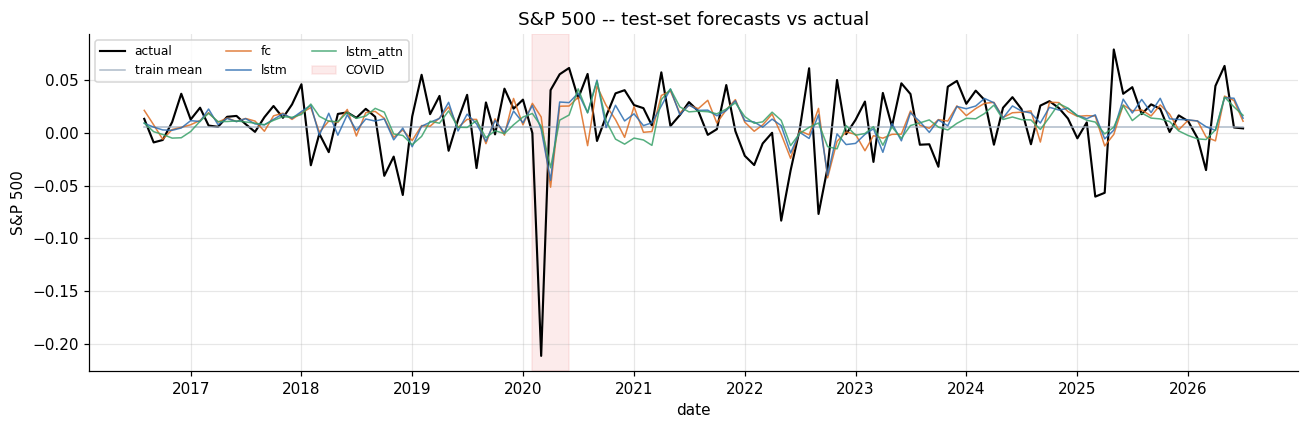

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test_dates, Y_test, color="black", lw=1.4, label="actual")
for name, c in [("train mean", "#a0aec0"), ("fc", "#dd6b20"),
                ("lstm", "#2b6cb0"), ("lstm_attn", "#38a169")]:
    ax.plot(test_dates, all_predictions[name], lw=1.0, alpha=0.85, color=c, label=name)
ax.axvspan(np.datetime64(CRISIS_START), np.datetime64(CRISIS_END),
           color="#e53e3e", alpha=0.10, label=CRISIS_NAME)
ax.set_title(f"{SERIES} -- test-set forecasts vs actual")
ax.set_xlabel("date"); ax.set_ylabel(SERIES); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

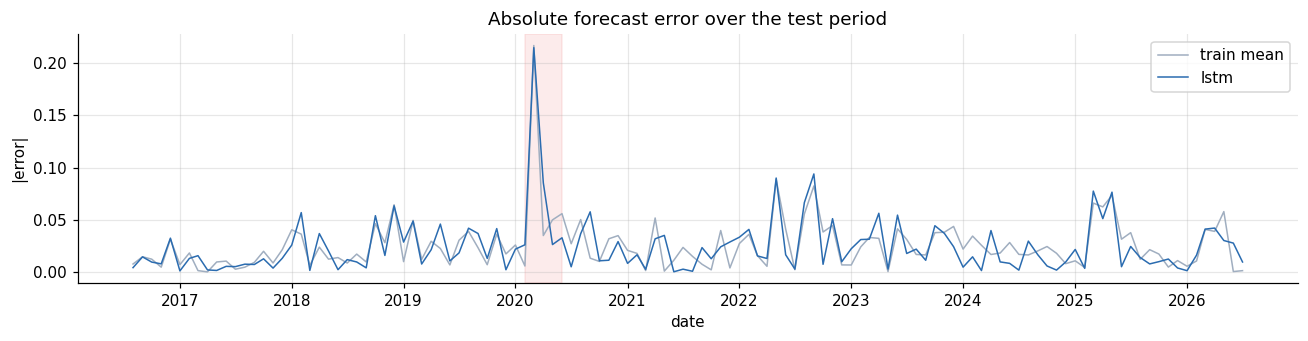

10 worst LSTM months:
      date    actual  lstm_pred  abs_error
2020-03-01 -0.211562   0.003407   0.214969
2022-09-01 -0.076961   0.017019   0.093980
2022-05-01 -0.083292   0.006774   0.090065
2020-04-01  0.040487  -0.045018   0.085504
2025-03-01 -0.060535   0.017016   0.077552
2025-05-01  0.079004   0.002476   0.076528
2022-08-01  0.061189  -0.005376   0.066565
2018-12-01 -0.058960   0.004467   0.063427
2020-09-01 -0.007752   0.049942   0.057694
2018-02-01 -0.030809   0.026137   0.056945


In [ ]:
fig, ax = plt.subplots(figsize=(12, 3.2))
for name, c in [("train mean", "#a0aec0"), ("lstm", "#2b6cb0")]:
    ax.plot(test_dates, np.abs(all_predictions[name] - Y_test), lw=1.0, color=c, label=name)
ax.axvspan(np.datetime64(CRISIS_START), np.datetime64(CRISIS_END),
           color="#e53e3e", alpha=0.10)
ax.set_title("Absolute forecast error over the test period")
ax.set_xlabel("date"); ax.set_ylabel("|error|"); ax.legend()
plt.tight_layout(); plt.show()

err = np.abs(all_predictions["lstm"] - Y_test)
worst = pd.DataFrame({"date": test_dates, "actual": Y_test,
                      "lstm_pred": all_predictions["lstm"], "abs_error": err})
print("10 worst LSTM months:")
print(worst.sort_values("abs_error", ascending=False).head(10).to_string(index=False))

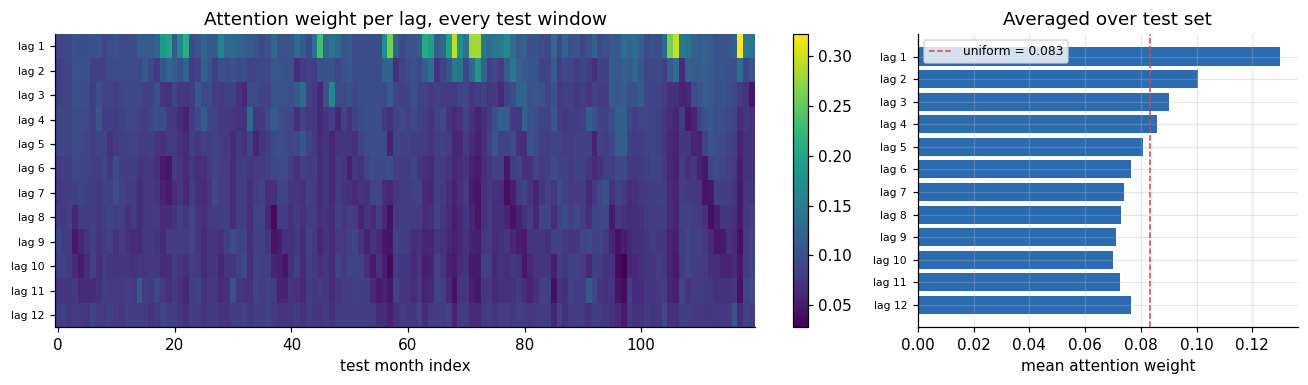

mean attention, lag 12 -> lag 1: [0.0764 0.0726 0.0701 0.071  0.0728 0.0738 0.0766 0.0807 0.0856 0.09
 0.1005 0.1299]


In [ ]:
m = neural["lstm_attn"]["models"][0]
with torch.no_grad():
    _, attn = m(Xte, return_attn=True)
attn = attn.numpy()

lag_labels = [f"lag {P_LAGS - i}" for i in range(P_LAGS)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6),
                         gridspec_kw={"width_ratios": [2, 1]})

im = axes[0].imshow(attn.T, aspect="auto", cmap="viridis", origin="lower")
axes[0].set_yticks(range(P_LAGS)); axes[0].set_yticklabels(lag_labels, fontsize=7)
axes[0].set_xlabel("test month index"); axes[0].set_title("Attention weight per lag, every test window")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=0.03)

axes[1].barh(range(P_LAGS), attn.mean(0), color="#2b6cb0")
axes[1].axvline(1 / P_LAGS, color="#e53e3e", ls="--", lw=1, label=f"uniform = {1/P_LAGS:.3f}")
axes[1].set_yticks(range(P_LAGS)); axes[1].set_yticklabels(lag_labels, fontsize=7)
axes[1].set_xlabel("mean attention weight"); axes[1].set_title("Averaged over test set")
axes[1].legend(fontsize=8)

plt.tight_layout(); plt.show()
print("mean attention, lag 12 -> lag 1:", np.round(attn.mean(0), 4))

In [ ]:
LOSS_SEEDS = list(range(10))
huber_preds, huber_models = [], []

for s in LOSS_SEEDS:
    m, _, p = train_one("lstm", best_cfg["lstm"], seed=s, loss_name="huber")
    huber_preds.append(p); huber_models.append(m)

huber_P = np.stack(huber_preds)
huber_mean_pred = huber_P.mean(0)
all_predictions["lstm_huber"] = huber_mean_pred

print(f"Huber delta used: {HUBER_DELTA:.4f}")
print(f"config (shared with MSE LSTM): {best_cfg['lstm']}")

Huber delta used: 0.0163
config (shared with MSE LSTM): {'hidden': 32, 'n_layers': 1, 'dropout': 0.1, 'lr': 0.003, 'batch': 64}


In [ ]:
loss_compare = era_table({"lstm (MSE)": all_predictions["lstm"],
                           "lstm (Huber)": all_predictions["lstm_huber"]})
print(loss_compare.to_string(float_format=lambda v: f"{v:,.6f}"))

s, p = dm_test(all_predictions["lstm_huber"][~crisis_mask],
               all_predictions["lstm"][~crisis_mask], Y_test[~crisis_mask])
better = "Huber" if s < 0 else "MSE"
verdict = f"{better} better, p={p:.4f}" if p < 0.05 else f"no significant difference (p={p:.4f})"
print(f"\nDM test, Huber vs MSE LSTM (ex-crisis): DM={s:+.3f}   {verdict}")

              RMSE all  RMSE ex-COVID  RMSE COVID  MAE all  MAE ex-COVID  MAE COVID
model                                                                              
lstm (MSE)    0.036489       0.030044    0.105806 0.024493      0.022203   0.077145
lstm (Huber)  0.036327       0.029957    0.105028 0.024523      0.022322   0.075165

DM test, Huber vs MSE LSTM (ex-crisis): DM=-0.193   no significant difference (p=0.8468)


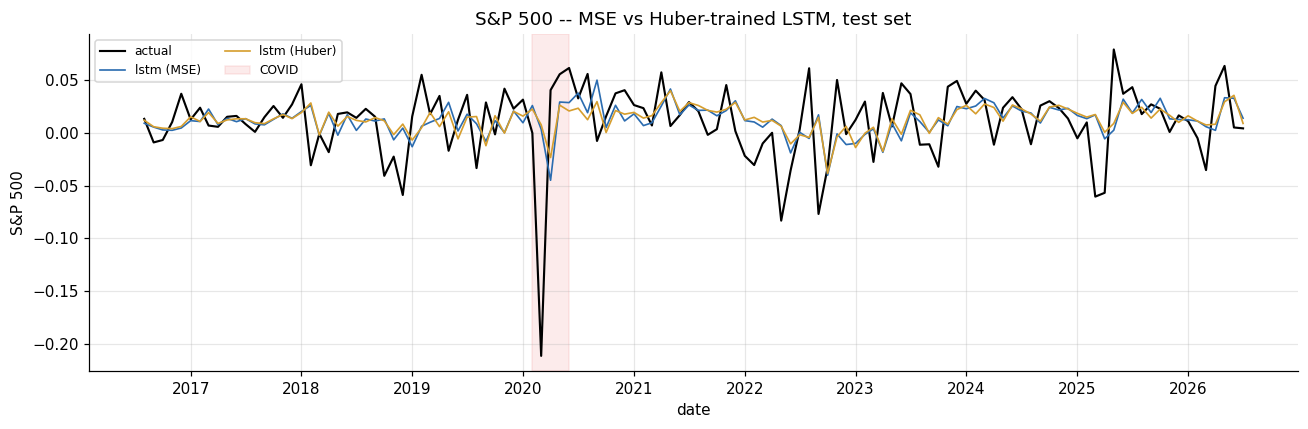

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test_dates, Y_test, color="black", lw=1.4, label="actual")
ax.plot(test_dates, all_predictions["lstm"], lw=1.1, color="#2b6cb0", label="lstm (MSE)")
ax.plot(test_dates, all_predictions["lstm_huber"], lw=1.1, color="#d69e2e", label="lstm (Huber)")
ax.axvspan(np.datetime64(CRISIS_START), np.datetime64(CRISIS_END),
           color="#e53e3e", alpha=0.10, label=CRISIS_NAME)
ax.set_title(f"{SERIES} -- MSE vs Huber-trained LSTM, test set")
ax.set_xlabel("date"); ax.set_ylabel(SERIES); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()